# Week 1 Jupyter Notebook — Integrated Capstone

## Central project questions

**Breast Cancer Wisconsin Diagnostic:** Can continuous cell-geometry measurements predict `radius_mean`, and how do polynomial and interaction terms affect predictive performance when the predictors are highly correlated?

**Cervical Cancer Risk Factors:** Can demographic, reproductive, and behavioral risk factors predict patient `Age`, and which continuous/categorical features contribute useful information after accounting for nonlinear and interaction effects?

These are **regression practice questions**. They intentionally use continuous targets so that the Week 1 linear-regression techniques are appropriate. The models are not presented as clinical diagnostic tools.

The notebook gives the two datasets equal attention and documents the modeling decisions, diagnostics, and conclusions that can later be summarized in Milestone One.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def regression_metrics(model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    }

def plot_actual_vs_pred(y_true, y_pred, title):
    plt.figure(figsize=(6,5))
    plt.scatter(y_true, y_pred, alpha=0.6)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, linestyle="--")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(title)
    plt.show()

## 1. Load and inspect both datasets

The cervical dataset uses `?` for missing values, so those entries are converted to `NaN`. The breast dataset comes without column names; the names below follow the UCI Wisconsin Diagnostic Breast Cancer data dictionary.

In [2]:
# Cervical cancer risk-factor data
cervical = pd.read_csv("risk_factors_cervical_cancer.csv").replace("?", np.nan)
cervical = cervical.apply(pd.to_numeric, errors="coerce")

# Breast Cancer Wisconsin Diagnostic data
breast_columns = [
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]
breast = pd.read_csv("wdbc.data", header=None, names=breast_columns)

print("Cervical shape:", cervical.shape)
print("Breast shape:", breast.shape)
display(cervical.head())
display(breast.head())

Cervical shape: (858, 36)
Breast shape: (569, 32)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,IUD (years),STDs,STDs (number),STDs:condylomatosis,STDs:cervical condylomatosis,STDs:vaginal condylomatosis,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:AIDS,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Dataset 1 — Cervical Cancer Risk Factors

### Exploratory data review

In [3]:
print("Missing-value rate (top 10):")
display(cervical.isna().mean().sort_values(ascending=False).head(10).to_frame("missing_rate"))

print("\nAge summary:")
display(cervical["Age"].describe().to_frame("Age"))

binary_cervical = [
    c for c in cervical.columns
    if set(cervical[c].dropna().unique()).issubset({0,1})
]
continuous_cervical = [
    c for c in cervical.columns
    if c not in binary_cervical
]

# Exclude diagnostic/screening outcomes from the predictor set for this regression question.
excluded_cervical = [
    "Dx:Cancer","Dx:CIN","Dx:HPV","Dx",
    "Hinselmann","Schiller","Citology","Biopsy"
]
risk_binary_cervical = [c for c in binary_cervical if c not in excluded_cervical]
risk_continuous_cervical = [
    c for c in continuous_cervical
    if c != "Age"
]

print("Categorical/binary features used:", len(risk_binary_cervical))
print(risk_binary_cervical)
print("\nContinuous features used:", len(risk_continuous_cervical))
print(risk_continuous_cervical)

Missing-value rate (top 10):


,missing_rate
STDs: Time since first diagnosis,0.917249
STDs: Time since last diagnosis,0.917249
IUD,0.136364
IUD (years),0.136364
Hormonal Contraceptives,0.125874
Hormonal Contraceptives (years),0.125874
STDs:HPV,0.122378
STDs:AIDS,0.122378
STDs:Hepatitis B,0.122378
STDs:HIV,0.122378



Age summary:


,Age
count,858.000000
mean,26.820513
std,8.497948
min,13.000000
25%,20.000000
50%,25.000000
75%,32.000000
max,84.000000


Categorical/binary features used: 16
['Smokes', 'Hormonal Contraceptives', 'IUD', 'STDs', 'STDs:condylomatosis', 'STDs:cervical condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:AIDS', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV']

Continuous features used: 11
['Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)', 'STDs: Number of diagnosis', 'STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']


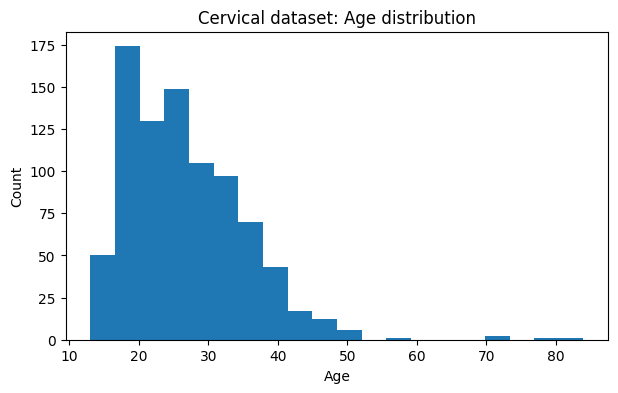

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes (years),Smokes (packs/year),Hormonal Contraceptives (years),IUD (years)
Age,1.00,0.09,0.37,0.55,0.22,0.13,0.29,0.22
Number of sexual partners,0.09,1.00,-0.15,0.08,0.19,0.18,0.02,0.00
First sexual intercourse,0.37,-0.15,1.00,-0.06,-0.06,-0.06,0.01,-0.03
Num of pregnancies,0.55,0.08,-0.06,1.00,0.18,0.10,0.22,0.15
Smokes (years),0.22,0.19,-0.06,0.18,1.00,0.72,0.05,0.04
Smokes (packs/year),0.13,0.18,-0.06,0.10,0.72,1.00,0.04,0.02
Hormonal Contraceptives (years),0.29,0.02,0.01,0.22,0.05,0.04,1.00,0.00
IUD (years),0.22,0.00,-0.03,0.15,0.04,0.02,0.00,1.00


In [4]:
# Basic visualization of the continuous target and selected risk factors
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(cervical["Age"].dropna(), bins=20)
ax.set_xlabel("Age")
ax.set_ylabel("Count")
ax.set_title("Cervical dataset: Age distribution")
plt.show()

selected_cervical = [
    "Age", "Number of sexual partners", "First sexual intercourse",
    "Num of pregnancies", "Smokes (years)", "Smokes (packs/year)",
    "Hormonal Contraceptives (years)", "IUD (years)"
]
display(cervical[selected_cervical].corr(numeric_only=True).round(2))

### Baseline linear regression with categorical and continuous features

Binary variables are treated as categorical features through one-hot encoding, while continuous variables are imputed and standardized. The target is `Age`.

In [5]:
X_c = cervical[risk_binary_cervical + risk_continuous_cervical]
y_c = cervical["Age"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_c, y_c, test_size=0.20, random_state=RANDOM_STATE
)

c_cat = risk_binary_cervical
c_num = risk_continuous_cervical

c_preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))
    ]), c_cat),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), c_num)
])

c_linear = Pipeline([
    ("preprocess", c_preprocessor),
    ("model", LinearRegression())
])

c_linear.fit(Xc_train, yc_train)
c_base_metrics = regression_metrics(c_linear, Xc_test, yc_test)
pd.DataFrame([c_base_metrics], index=["Cervical baseline"])

,R2,RMSE,MAE
Cervical baseline,0.505434,6.783693,4.699884


### Polynomial terms and interaction terms

To keep the model interpretable, polynomial/interaction expansion is applied to a focused set of continuous risk factors rather than every column. Degree 2 creates squared terms and pairwise interactions. The comparison is against a linear model using the same focused variables.

In [6]:
poly_c = [
    "Number of sexual partners",
    "First sexual intercourse",
    "Num of pregnancies",
    "Smokes (years)",
    "Smokes (packs/year)",
    "Hormonal Contraceptives (years)",
    "IUD (years)"
]

Xcp_train, Xcp_test, ycp_train, ycp_test = train_test_split(
    cervical[poly_c], cervical["Age"], test_size=0.20, random_state=RANDOM_STATE
)

poly_pipeline_c = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

poly_pipeline_c.fit(Xcp_train, ycp_train)
poly_metrics = regression_metrics(poly_pipeline_c, Xcp_test, ycp_test)

linear_focused_c = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_focused_c.fit(Xcp_train, ycp_train)
linear_focused_metrics = regression_metrics(linear_focused_c, Xcp_test, ycp_test)

pd.DataFrame(
    [linear_focused_metrics, poly_metrics],
    index=["Cervical focused linear", "Cervical polynomial + interactions"]
).round(3)

,R2,RMSE,MAE
Cervical focused linear,0.508,6.764,4.651
Cervical polynomial + interactions,0.435,7.254,4.581


### Multicollinearity and VIF

Variance Inflation Factor (VIF) measures how much the variance of an estimated coefficient is inflated because a predictor can be explained by other predictors. High VIF values are a warning sign for unstable coefficient estimates. Here it is used as a diagnostic, not as an automatic rule for deleting variables.

,feature,VIF
3,Smokes (years),2.16
4,Smokes (packs/year),2.12
2,Num of pregnancies,1.11
0,Number of sexual partners,1.06
5,Hormonal Contraceptives (years),1.05
1,First sexual intercourse,1.03
6,IUD (years),1.02


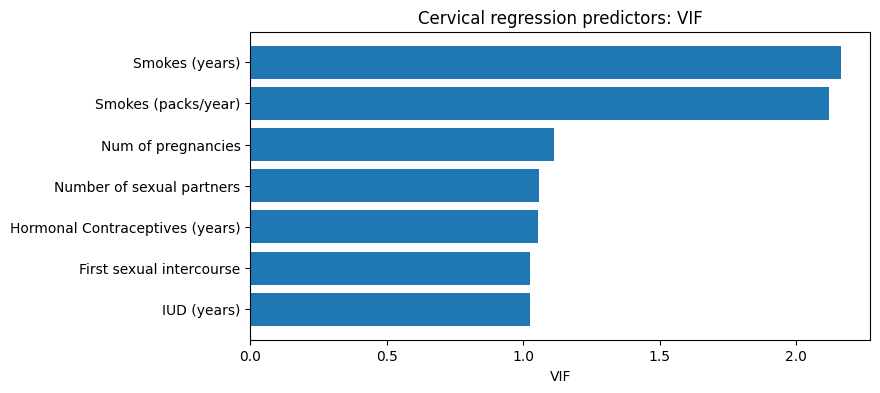

In [7]:
def vif_table(df, features):
    X = df[features].copy()
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=features)
    X = sm_add_constant(X)
    rows = []
    for i, col in enumerate(X.columns):
        if col == "const":
            continue
        rows.append((col, variance_inflation_factor(X.values, i)))
    return pd.DataFrame(rows, columns=["feature","VIF"]).sort_values("VIF", ascending=False)

# Small helper avoids requiring a statsmodels formula API.
from statsmodels.api import add_constant as sm_add_constant

c_vif_features = [
    "Number of sexual partners", "First sexual intercourse",
    "Num of pregnancies", "Smokes (years)", "Smokes (packs/year)",
    "Hormonal Contraceptives (years)", "IUD (years)"
]
c_vif = vif_table(cervical, c_vif_features)
display(c_vif.round(2))

plt.figure(figsize=(8,4))
plt.barh(c_vif["feature"], c_vif["VIF"])
plt.xlabel("VIF")
plt.title("Cervical regression predictors: VIF")
plt.gca().invert_yaxis()
plt.show()

### Cervical conclusions for Week 1

Use the output above to write 2–4 evidence-based observations in your final submission. In particular, comment on:

1. Whether adding squared/interaction terms changes test-set R²/RMSE.
2. Which variables show the largest VIF and what that implies for coefficient interpretation.
3. Whether the model's predictive performance is meaningfully different from the baseline.
4. The distinction between association/prediction and clinical causation.

## 3. Dataset 2 — Breast Cancer Wisconsin Diagnostic

### Exploratory data review

Diagnosis counts (descriptive only; diagnosis is not used as a predictor here):


diagnosis
B    357
M    212
Name: count, dtype: int64

Number of continuous predictors: 29


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268


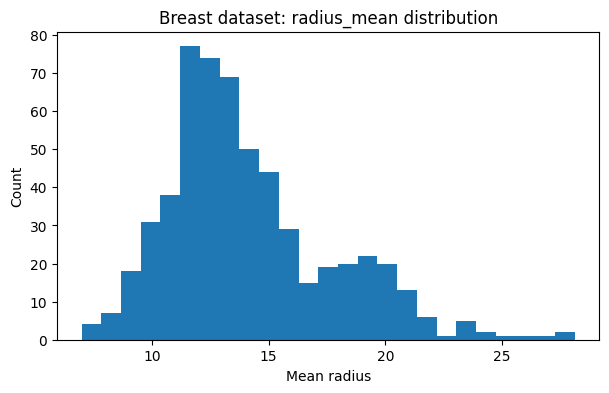

In [8]:
print("Diagnosis counts (descriptive only; diagnosis is not used as a predictor here):")
display(breast["diagnosis"].value_counts())

breast_predictors = [c for c in breast.columns if c not in ["id", "diagnosis", "radius_mean"]]
print("Number of continuous predictors:", len(breast_predictors))

display(breast[["radius_mean","texture_mean","perimeter_mean","area_mean",
                "compactness_mean","concavity_mean"]].describe().T)

plt.figure(figsize=(7,4))
plt.hist(breast["radius_mean"], bins=25)
plt.xlabel("Mean radius")
plt.ylabel("Count")
plt.title("Breast dataset: radius_mean distribution")
plt.show()

### Baseline regression with continuous features

The target is `radius_mean`. The diagnosis field is deliberately excluded to avoid using the outcome label as a predictor.

In [9]:
X_b = breast[breast_predictors]
y_b = breast["radius_mean"]

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_b, y_b, test_size=0.20, random_state=RANDOM_STATE
)

b_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

b_linear = Pipeline([
    ("preprocess", b_preprocessor),
    ("model", LinearRegression())
])

b_linear.fit(Xb_train, yb_train)
b_base_metrics = regression_metrics(b_linear, Xb_test, yb_test)
pd.DataFrame([b_base_metrics], index=["Breast baseline"]).round(3)

,R2,RMSE,MAE
Breast baseline,1.0,0.069,0.044


### Polynomial and interaction terms

The focused predictors are selected because they represent different cell measurements while also making it possible to examine multicollinearity. Degree-2 expansion adds nonlinear terms and pairwise interactions.

In [10]:
poly_b = [
    "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",
    "compactness_mean", "concavity_mean"
]

Xbp_train, Xbp_test, ybp_train, ybp_test = train_test_split(
    breast[poly_b], breast["radius_mean"], test_size=0.20, random_state=RANDOM_STATE
)

linear_focused_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_focused_b.fit(Xbp_train, ybp_train)
b_focused_metrics = regression_metrics(linear_focused_b, Xbp_test, ybp_test)

poly_pipeline_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
poly_pipeline_b.fit(Xbp_train, ybp_train)
b_poly_metrics = regression_metrics(poly_pipeline_b, Xbp_test, ybp_test)

pd.DataFrame(
    [b_focused_metrics, b_poly_metrics],
    index=["Breast focused linear", "Breast polynomial + interactions"]
).round(3)

,R2,RMSE,MAE
Breast focused linear,0.999,0.086,0.049
Breast polynomial + interactions,1.000,0.073,0.044


### Breast multicollinearity and VIF

Geometry measures such as perimeter and area are mathematically related to size, so multicollinearity is expected. VIF helps quantify that relationship.

,feature,VIF
1,perimeter_mean,49.58
2,area_mean,47.35
4,compactness_mean,7.45
5,concavity_mean,7.36
3,smoothness_mean,2.00
0,texture_mean,1.18


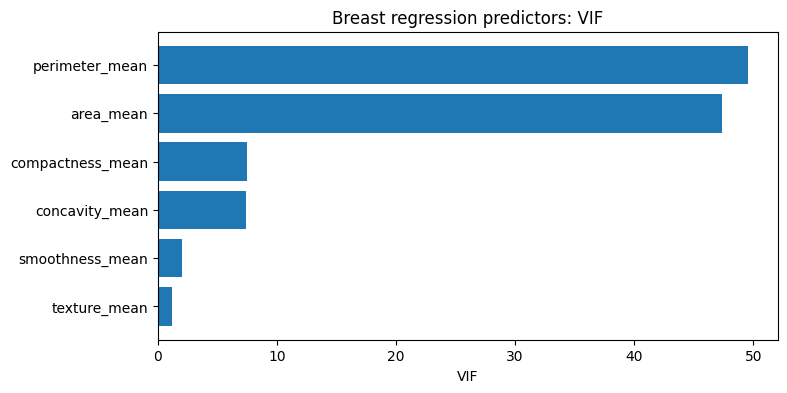

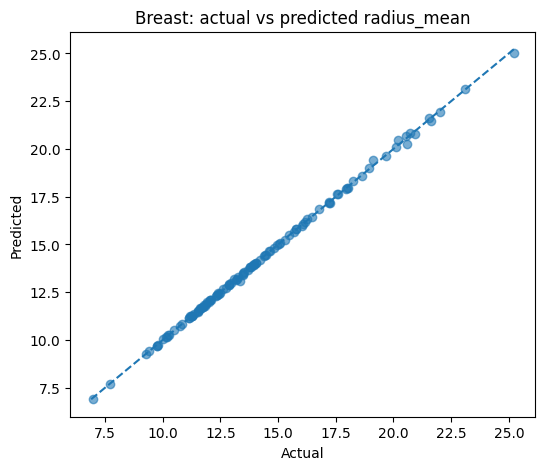

In [11]:
b_vif = vif_table(breast, [
    "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean"
])
display(b_vif.round(2))

plt.figure(figsize=(8,4))
plt.barh(b_vif["feature"], b_vif["VIF"])
plt.xlabel("VIF")
plt.title("Breast regression predictors: VIF")
plt.gca().invert_yaxis()
plt.show()

plot_actual_vs_pred(
    ybp_test,
    poly_pipeline_b.predict(Xbp_test),
    "Breast: actual vs predicted radius_mean"
)

### Breast conclusions for Week 1

Use the model outputs to record 2–4 observations. Focus on the effect of polynomial/interaction terms, the magnitude of multicollinearity, and how coefficient interpretation becomes more difficult when correlated predictors and interaction terms are present.

## 4. Cross-dataset Week 1 comparison

The two datasets deliberately use different continuous targets and feature structures. This makes the comparison useful: the cervical model contains many binary/categorical risk indicators plus continuous variables, while the breast model is dominated by continuous geometric measurements.

In your Milestone One narrative, compare **model behavior and diagnostics**, not just the raw R² values. The target scales differ, so RMSE values are not directly comparable across datasets.

In [12]:
week1_summary = pd.DataFrame({
    "Dataset": ["Cervical", "Breast"],
    "Baseline_R2": [c_base_metrics["R2"], b_base_metrics["R2"]],
    "Baseline_RMSE": [c_base_metrics["RMSE"], b_base_metrics["RMSE"]],
    "Polynomial_R2": [poly_metrics["R2"], b_poly_metrics["R2"]],
    "Polynomial_RMSE": [poly_metrics["RMSE"], b_poly_metrics["RMSE"]]
})
display(week1_summary.round(3))

,Dataset,Baseline_R2,Baseline_RMSE,Polynomial_R2,Polynomial_RMSE
0,Cervical,0.505,6.784,0.435,7.254
1,Breast,1.000,0.069,1.000,0.073
